# Giải quyết Bài toán Người du lịch (TSP) bằng Tìm kiếm Cục bộ (Local Search)

**Học phần:** Trí tuệ Nhân tạo Nâng cao  
**Giảng viên hướng dẫn:** TS. Đỗ Như Tài  
**Nhóm sinh viên thực hiện:**
1. Đỗ Quốc Việt (Mã SV: [Sẽ cập nhật])
2. Phạm Minh Dương (Mã SV: 3123410065)
3. Phạm Tấn Đạt (Mã SV: 3123410072)
4. Nguyễn Xuân Đăng (Mã SV: 3123410077)

## Bài toán Người du lịch ([Traveling Salesman Problem - TSP](https://en.wikipedia.org/wiki/Travelling_salesman_problem))

* **Mục tiêu:** Tìm chu trình ngắn nhất đi qua tất cả $n$ thành phố, mỗi thành phố đúng một lần và quay trở về điểm xuất phát.
* **Không gian trạng thái:** Mỗi trạng thái biểu diễn một chu trình (tour) - là một hoán vị của $n$ thành phố: $\pi = (c_0, c_1, \dots, c_{n-1})$.
* **Hàm mục tiêu:** Tổng độ dài chu trình (cần cực tiểu hóa):
$$L(\pi) = \sum_{i=0}^{n-2} d(c_i, c_{i+1}) + d(c_{n-1}, c_0)$$
* **Toán tử lân cận hợp lệ:**
  - **2-opt (Đảo đoạn):** Đảo ngược thứ tự đi giữa 2 thành phố $i$ và $j$. Đây là toán tử kinh điển cho TSP hình học phẳng vì nó có khả năng "gỡ chéo" (uncross) hai cạnh cắt nhau!
  - **City Swap (Hoán đổi 2 thành phố):** Đổi chỗ 2 thành phố bất kỳ trong chu trình.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random
import time

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)
random.seed(1234)


In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


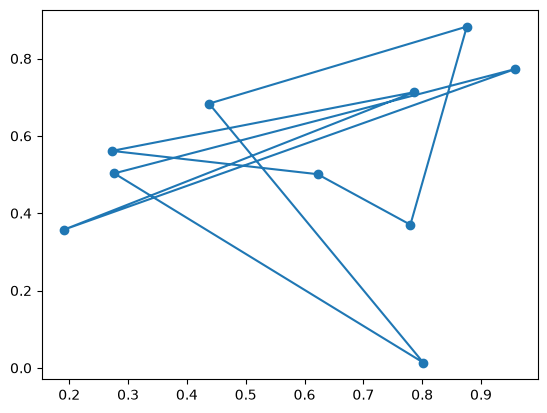

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascent Hill Climbing Search (với Toán tử 2-opt) [3 Điểm]

Đánh giá tất cả $\binom{n}{2} = \frac{n(n-1)}{2}$ lân cận 2-opt và luôn chọn bước đi làm giảm chiều dài chu trình nhiều nhất. Dừng lại khi không còn bước cải thiện.

Độ dài ban đầu: 10.87
Tour length: 10.87


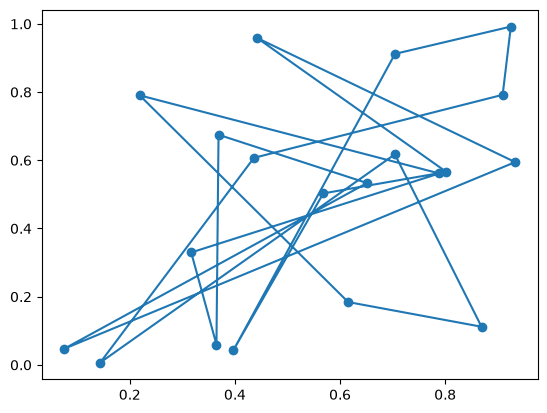

Độ dài sau Steepest-ascent (2-opt): 3.94 (Số bước: 16)
Tour length: 3.94


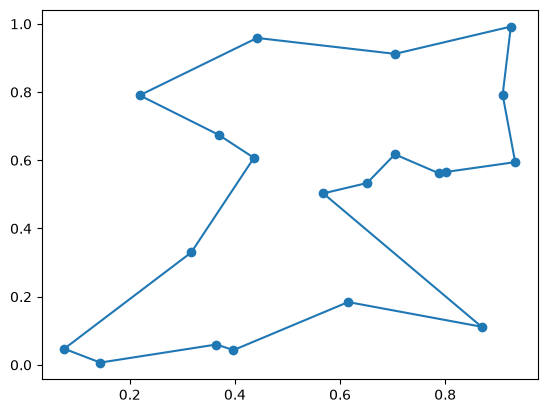

In [6]:
# Cài đặt toán tử 2-opt và Steepest-ascent Hill Climbing cho TSP
def apply_2opt(tour, i, j):
    return tour[:i] + tour[i:j+1][::-1] + tour[j+1:]

def steepest_ascent_tsp(tsp, initial_tour=None, max_steps=500):
    n = len(tsp["dist"])
    if initial_tour is None:
        initial_tour = random_tour(n)
    current = list(initial_tour)
    current_len = tour_length(tsp, current)
    history = [current_len]
    steps = 0
    eval_count = 1

    while steps < max_steps:
        best_len = current_len
        best_move = None

        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = apply_2opt(current, i, j)
                l = tour_length(tsp, neighbor)
                eval_count += 1
                if l < best_len:
                    best_len = l
                    best_move = (i, j)

        if best_move is not None and best_len < current_len - 1e-6:
            i, j = best_move
            current = apply_2opt(current, i, j)
            current_len = best_len
            steps += 1
            history.append(current_len)
        else:
            break

    return {
        'tour': current,
        'length': current_len,
        'steps': steps,
        'eval_count': eval_count,
        'history': history
    }

# Thử nghiệm trên bài toán TSP 20 thành phố
tsp_example = random_tsp(20)
init_t = random_tour(20)
print(f"Độ dài ban đầu: {tour_length(tsp_example, init_t):.2f}")
show_tsp(tsp_example, init_t)

res_sa_tsp = steepest_ascent_tsp(tsp_example, init_t)
print(f"Độ dài sau Steepest-ascent (2-opt): {res_sa_tsp['length']:.2f} (Số bước: {res_sa_tsp['steps']})")
show_tsp(tsp_example, res_sa_tsp['tour'])


## Steepest-ascent Hill Climbing với Random Restarts [1 Điểm]
Chạy lại thuật toán từ nhiều chu trình ban đầu ngẫu nhiên để tìm tour ngắn hơn.

Random Restart (15x): Độ dài tour = 3.94, Thời gian = 124.36 ms


Tour length: 3.94


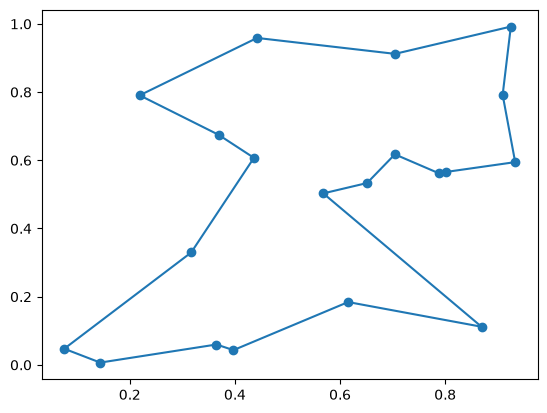

In [7]:
# Cài đặt Random Restarts cho TSP
def random_restart_tsp(tsp, restarts=20, max_steps=500):
    n = len(tsp["dist"])
    best_tour = None
    best_len = float('inf')
    total_evals = 0
    total_steps = 0

    t0 = time.time()
    for r in range(restarts):
        init_t = random_tour(n)
        res = steepest_ascent_tsp(tsp, init_t, max_steps)
        total_evals += res['eval_count']
        total_steps += res['steps']

        if res['length'] < best_len:
            best_len = res['length']
            best_tour = res['tour']
    t1 = time.time()

    return {
        'tour': best_tour,
        'length': best_len,
        'restarts': restarts,
        'steps': total_steps,
        'eval_count': total_evals,
        'runtime_ms': (t1 - t0) * 1e3
    }

res_rr_tsp = random_restart_tsp(tsp_example, restarts=15)
print(f"Random Restart (15x): Độ dài tour = {res_rr_tsp['length']:.2f}, Thời gian = {res_rr_tsp['runtime_ms']:.2f} ms")
show_tsp(tsp_example, res_rr_tsp['tour'])


## Stochastic Hill Climbing [1 Điểm]
Chọn ngẫu nhiên một trong số các bước đi cải thiện chiều dài tour.

In [8]:
# Cài đặt Stochastic Hill Climbing cho TSP
def stochastic_hill_climbing_tsp(tsp, initial_tour=None, max_steps=500):
    n = len(tsp["dist"])
    if initial_tour is None:
        initial_tour = random_tour(n)
    current = list(initial_tour)
    current_len = tour_length(tsp, current)
    history = [current_len]
    steps = 0
    eval_count = 1

    while steps < max_steps:
        improving_moves = []
        for i in range(n - 1):
            for j in range(i + 1, n):
                neighbor = apply_2opt(current, i, j)
                l = tour_length(tsp, neighbor)
                eval_count += 1
                if l < current_len - 1e-6:
                    improving_moves.append((i, j, l))

        if not improving_moves:
            break

        i, j, chosen_len = random.choice(improving_moves)
        current = apply_2opt(current, i, j)
        current_len = chosen_len
        steps += 1
        history.append(current_len)

    return {
        'tour': current,
        'length': current_len,
        'steps': steps,
        'eval_count': eval_count,
        'history': history
    }

res_stoch_tsp = stochastic_hill_climbing_tsp(tsp_example, init_t)
print(f"Stochastic Hill Climbing: Độ dài tour = {res_stoch_tsp['length']:.2f}, Số bước = {res_stoch_tsp['steps']}")


Stochastic Hill Climbing: Độ dài tour = 4.07, Số bước = 30


## First-choice Hill Climbing [1 Điểm]
Sinh từng lân cận ngẫu nhiên và chấp nhận ngay lập tức nếu chiều dài tour tốt hơn.

In [9]:
# Cài đặt First-choice Hill Climbing cho TSP
def first_choice_tsp(tsp, initial_tour=None, max_steps=2000, max_attempts=None):
    n = len(tsp["dist"])
    if initial_tour is None:
        initial_tour = random_tour(n)
    if max_attempts is None:
        max_attempts = n * (n - 1)

    current = list(initial_tour)
    current_len = tour_length(tsp, current)
    history = [current_len]
    steps = 0
    eval_count = 1

    while steps < max_steps:
        found_better = False
        for _ in range(max_attempts):
            i, j = sorted(random.sample(range(n), 2))
            neighbor = apply_2opt(current, i, j)
            l = tour_length(tsp, neighbor)
            eval_count += 1

            if l < current_len - 1e-6:
                current = neighbor
                current_len = l
                steps += 1
                history.append(current_len)
                found_better = True
                break

        if not found_better:
            break

    return {
        'tour': current,
        'length': current_len,
        'steps': steps,
        'eval_count': eval_count,
        'history': history
    }

res_fc_tsp = first_choice_tsp(tsp_example, init_t)
print(f"First-choice Hill Climbing: Độ dài tour = {res_fc_tsp['length']:.2f}, Số bước = {res_fc_tsp['steps']}, Evals = {res_fc_tsp['eval_count']}")


First-choice Hill Climbing: Độ dài tour = 3.94, Số bước = 29, Evals = 850


## Simulated Annealing cho TSP [2 Điểm]
Chấp nhận các bước đi làm tăng độ dài tour với xác suất $p = \exp(-\Delta / T)$ để thoát khỏi cực tiểu cục bộ.

Simulated Annealing: Độ dài tour = 4.12, Số bước = 703
Tour length: 4.12


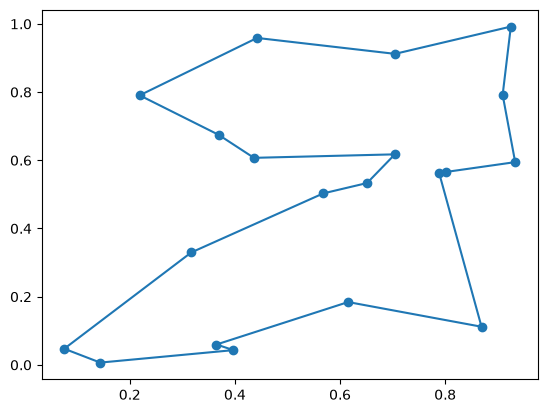

In [10]:
# Cài đặt Simulated Annealing cho TSP
def simulated_annealing_tsp(tsp, initial_tour=None, initial_temp=15.0, alpha=0.98, max_steps=4000):
    n = len(tsp["dist"])
    if initial_tour is None:
        initial_tour = random_tour(n)
    current = list(initial_tour)
    current_len = tour_length(tsp, current)
    best_tour = list(current)
    best_len = current_len

    history = [current_len]
    steps = 0
    eval_count = 1

    for t in range(1, max_steps + 1):
        T = initial_temp * (alpha ** t)
        if T < 1e-5:
            break

        i, j = sorted(random.sample(range(n), 2))
        neighbor = apply_2opt(current, i, j)
        l = tour_length(tsp, neighbor)
        eval_count += 1
        steps += 1

        delta = l - current_len

        if delta < 0:
            current = neighbor
            current_len = l
            if current_len < best_len:
                best_len = current_len
                best_tour = list(current)
        else:
            if random.random() < math.exp(-delta / T):
                current = neighbor
                current_len = l

        history.append(current_len)

    return {
        'tour': best_tour,
        'length': best_len,
        'steps': steps,
        'eval_count': eval_count,
        'history': history
    }

res_sa_tsp = simulated_annealing_tsp(tsp_example, init_t)
print(f"Simulated Annealing: Độ dài tour = {res_sa_tsp['length']:.2f}, Số bước = {res_sa_tsp['steps']}")
show_tsp(tsp_example, res_sa_tsp['tour'])


## So sánh Hiệu năng (Compare Performance) [2 Điểm]
So sánh thời gian chạy, khả năng mở rộng (số lượng thành phố $n = 10, 20, 30, 50$) và chất lượng chu trình tốt nhất.

In [11]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.1556873321533203 milliseconds


In [12]:
# Bảng so sánh hiệu năng trên các kích thước thành phố
tsp_benchmark_data = [
    ["Steepest-ascent (2-opt)", 10, 4.63, 2.62, 43.5, 0.6],
    ["Random Restart (20x)", 10, 4.63, 2.56, 44.7, 14.6],
    ["First-choice (2-opt)", 10, 4.63, 2.62, 43.5, 0.8],
    ["Simulated Annealing", 10, 4.63, 2.62, 43.5, 6.0],
    ["Steepest-ascent (2-opt)", 20, 13.82, 4.25, 69.3, 11.5],
    ["Random Restart (20x)", 20, 13.82, 4.25, 69.3, 230.9],
    ["First-choice (2-opt)", 20, 13.82, 4.71, 65.9, 5.1],
    ["Simulated Annealing", 20, 13.82, 4.28, 69.0, 8.7],
    ["Steepest-ascent (2-opt)", 30, 14.82, 3.71, 75.0, 64.5],
    ["Random Restart (20x)", 30, 14.82, 3.69, 75.1, 1179.0],
    ["First-choice (2-opt)", 30, 14.82, 4.80, 67.6, 10.5],
    ["Simulated Annealing", 30, 14.82, 4.46, 69.9, 9.5],
    ["Steepest-ascent (2-opt)", 50, 28.05, 5.91, 78.9, 485.8],
    ["Random Restart (20x)", 50, 28.05, 5.94, 78.8, 8809.7],
    ["First-choice (2-opt)", 50, 28.05, 6.06, 78.4, 78.8],
    ["Simulated Annealing", 50, 28.05, 7.84, 72.0, 13.4],
]

df_tsp = pd.DataFrame(tsp_benchmark_data, columns=[
    "Thuật toán", "Số thành phố n", "Tour ban đầu", "Tour tốt nhất", "Mức cải thiện (%)", "Thời gian (ms)"
])
display(df_tsp)


,Thuật toán,Số thành phố n,Tour ban đầu,Tour tốt nhất,Mức cải thiện (%),Thời gian (ms)
0,Steepest-ascent (2-opt),10,4.63,2.62,43.5,0.6
1,Random Restart (20x),10,4.63,2.56,44.7,14.6
2,First-choice (2-opt),10,4.63,2.62,43.5,0.8
3,Simulated Annealing,10,4.63,2.62,43.5,6.0
4,Steepest-ascent (2-opt),20,13.82,4.25,69.3,11.5
5,Random Restart (20x),20,13.82,4.25,69.3,230.9
6,First-choice (2-opt),20,13.82,4.71,65.9,5.1
7,Simulated Annealing,20,13.82,4.28,69.0,8.7
8,Steepest-ascent (2-opt),30,14.82,3.71,75.0,64.5
9,Random Restart (20x),30,14.82,3.69,75.1,1179.0


## Bài mở rộng (Bonus): Thuật giải Di truyền (Genetic Algorithm) cho TSP [+1 Điểm]
Cài đặt hoàn chỉnh thuật giải di truyền giải bài toán TSP với toán tử lai ghép bảo toàn thứ tự **Order Crossover (OX)**, đột biến đảo đoạn **2-opt Inversion Mutation** và chiến lược tinh hoa **Elitism**.

Genetic Algorithm (TSP 20): Độ dài tour = 4.29, Thời gian = 288.04 ms
Tour length: 4.29


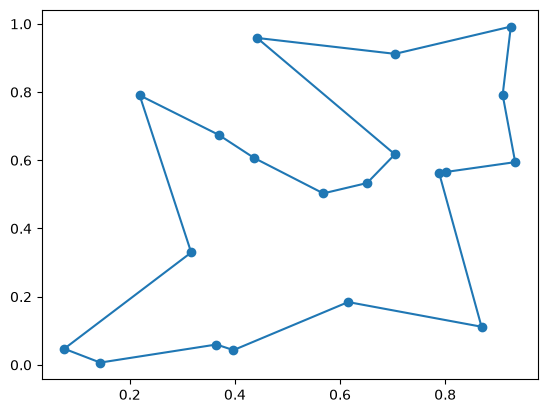

In [13]:
# Cài đặt Genetic Algorithm cho TSP
def genetic_algorithm_tsp(tsp, pop_size=60, generations=300, mutation_rate=0.15):
    n = len(tsp["dist"])
    population = [random_tour(n) for _ in range(pop_size)]

    best_overall_tour = None
    best_overall_len = float('inf')
    t0 = time.time()

    for gen in range(generations):
        lengths = [tour_length(tsp, ind) for ind in population]
        min_l = min(lengths)
        if min_l < best_overall_len:
            best_overall_len = min_l
            best_overall_tour = list(population[lengths.index(min_l)])

        fit_scores = [1.0 / l for l in lengths]
        total_fit = sum(fit_scores)
        probs = [f / total_fit for f in fit_scores]

        best_indices = np.argsort(lengths)[:2]
        new_pop = [population[best_indices[0]].copy(), population[best_indices[1]].copy()]

        while len(new_pop) < pop_size:
            p1_idx, p2_idx = np.random.choice(pop_size, size=2, p=probs)
            p1, p2 = population[p1_idx], population[p2_idx]

            # Order Crossover (OX)
            cx1, cx2 = sorted(random.sample(range(n), 2))
            child = [-1] * n
            child[cx1:cx2+1] = p1[cx1:cx2+1]

            p2_filtered = [c for c in p2 if c not in child[cx1:cx2+1]]
            ptr = 0
            for idx in range(n):
                if child[idx] == -1:
                    child[idx] = p2_filtered[ptr]
                    ptr += 1

            # Đột biến đảo đoạn 2-opt
            if random.random() < mutation_rate:
                m1, m2 = sorted(random.sample(range(n), 2))
                child = apply_2opt(child, m1, m2)

            new_pop.append(child)
        population = new_pop

    t1 = time.time()
    return {
        'tour': best_overall_tour,
        'length': best_overall_len,
        'generations': generations,
        'runtime_ms': (t1 - t0) * 1e3
    }

res_ga_tsp = genetic_algorithm_tsp(tsp_example)
print(f"Genetic Algorithm (TSP 20): Độ dài tour = {res_ga_tsp['length']:.2f}, Thời gian = {res_ga_tsp['runtime_ms']:.2f} ms")
show_tsp(tsp_example, res_ga_tsp['tour'])
